In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as t
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from lightgbm import LGBMClassifier

from sklearn.metrics import (
accuracy_score,
classification_report,
log_loss,
confusion_matrix
)

In [2]:
df=pd.read_csv("results.csv")
df

,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False
...,...,...,...,...,...,...,...,...,...
49542,2026-08-16,Malaysia,Vietnam,0,2,ASEAN Championship,Kuala Lumpur,Malaysia,False
49543,2026-08-18,Thailand,Singapore,1,2,ASEAN Championship,Bangkok,Thailand,False
49544,2026-08-19,Vietnam,Malaysia,2,0,ASEAN Championship,Hanoi,Vietnam,False
49545,2026-08-22,Thailand,Vietnam,0,2,ASEAN Championship,Bangkok,Thailand,False


In [3]:
df.head()
df.describe()
df['tournament'].value_counts()
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49547 entries, 0 to 49546
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        49547 non-null  object
 1   home_team   49547 non-null  object
 2   away_team   49547 non-null  object
 3   home_score  49547 non-null  int64 
 4   away_score  49547 non-null  int64 
 5   tournament  49547 non-null  object
 6   city        49547 non-null  object
 7   country     49547 non-null  object
 8   neutral     49547 non-null  bool  
dtypes: bool(1), int64(2), object(6)
memory usage: 3.1+ MB
None


In [4]:
df['home_score']=pd.to_numeric(
    df['home_score'], errors="coerce"
)
df['away_score']=pd.to_numeric(
    df['away_score'], errors="coerce"
)
df['date']=pd.to_datetime(df['date'])
df['year']=df['date'].dt.year

In [5]:
df=df.dropna(
    subset=["date",
            "home_score",
            "away_score",
            "home_team",
            "away_team",
            "tournament",
            "city",
            "country",
            "neutral"
           ]
)
df["neutral"]=(
    df["neutral"]
        .astype(str)
    .str.lower()
    .map({"true":1,"false":0, "1":1, "0":0})
)

df=df.dropna(
    subset=["neutral"])
df["neutral"]=df["neutral"].astype(int)


In [6]:
df["result"]=np.select(
    [
        df["home_score"] > df["away_score"],
        df["home_score"] == df["away_score"]
    ],
    [
        2,
        1
    ],
    default=0
)
print(df["result"].value_counts())
print(
    df["result"].value_counts(normalize=True)*100
)

features = [
    "home_team",
    "away_team",
    "tournament",
    "year",
    "neutral"
]
X=df[features]
y=df["result"]

result
2    24276
0    14010
1    11261
Name: count, dtype: int64
result
2    48.995903
0    28.276182
1    22.727915
Name: proportion, dtype: float64


In [7]:
categorical_features=[
    "home_team",
    "away_team",
    "tournament"
]
numerical_features=[
    "neutral",
    "year"
]
preprocessor=ColumnTransformer(
    transformers=[
        (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
        ),
(
    "numerical",
    "passthrough",
    numerical_features
)
    ]
)

In [8]:

class EloRating:

    def __init__(self, initial_rating=1500, K=32, home_advantage=100):
        self.initial_rating = initial_rating
        self.K = K
        self.home_advantage = home_advantage
        self.ratings = {}

    def get_rating(self, team):
        return self.ratings.get(team, self.initial_rating)

    def expected_score(self, home_elo, away_elo, neutral=False):
        advantage = 0 if neutral else self.home_advantage

        return 1 / (
            1 + 10 ** ((away_elo - home_elo - advantage) / 400)
        )

    def update(self, home, away, result, neutral=False):

        home_elo = self.get_rating(home)
        away_elo = self.get_rating(away)

        expected_home = self.expected_score(
            home_elo, away_elo, neutral
        )

        # 1 = Home win, 0.5 = Draw, 0 = Away win
        actual_home = result

        change = self.K * (actual_home - expected_home)

        self.ratings[home] = home_elo + change
        self.ratings[away] = away_elo - change

    def get_features(self, home, away, neutral=False):

        home_elo = self.get_rating(home)
        away_elo = self.get_rating(away)

        return {
            "home_elo": home_elo,
            "away_elo": away_elo,
            "elo_difference": home_elo - away_elo,
            "expected_home_elo": self.expected_score(
                home_elo, away_elo, neutral
            )
        }

    def fit_transform(self, df):

        df = df.sort_values("date").copy()
        features = []

        for _, row in df.iterrows():

            # Get Elo features before the match
            match_features = self.get_features(
                row["home_team"],
                row["away_team"],
                row["neutral"]
            )

            features.append(match_features)

            # Convert match result
            result = {
                0: 0,      # Away win
                1: 0.5,    # Draw
                2: 1       # Home win
            }[row["result"]]

            # Update ratings after the match
            self.update(
                row["home_team"],
                row["away_team"],
                result,
                row["neutral"]
            )

        elo_features = pd.DataFrame(
            features,
            index=df.index
        )

        return df.join(elo_features)


In [9]:
elo = EloRating(K=32, home_advantage=100)

df = elo.fit_transform(df)

In [10]:
df = df.sort_values("date").reset_index(drop=True)

split_index = int(len(df) * 0.80)
cutoff_date = df.iloc[split_index]["date"]

train_df = df[df["date"] < cutoff_date].copy()
test_df = df[df["date"] >= cutoff_date].copy()

print("Training:", train_df.shape)
print("Testing:", test_df.shape)

print("Training ends:", train_df["date"].max())
print("Testing starts:", test_df["date"].min())

Training: (39590, 15)
Testing: (9957, 15)
Training ends: 2016-03-28 00:00:00
Testing starts: 2016-03-29 00:00:00


In [11]:
elo_table = pd.DataFrame(
    elo.ratings.items(),
    columns=["Country", "Elo Rating"]
)

elo_table = elo_table.sort_values(
    "Elo Rating", ascending=False
)

print(elo_table.head(20))

         Country   Elo Rating
40         Spain  2110.676897
7      Argentina  2102.986041
12        France  2006.663480
1        England  1984.260085
33        Brazil  1974.168427
85      Colombia  1968.487499
49      Portugal  1958.153082
17   Netherlands  1917.299729
21       Germany  1916.208407
154      Morocco  1911.034587
11       Belgium  1904.768399
88       Ecuador  1899.523735
25         Italy  1894.441044
56        Mexico  1893.500764
35         Japan  1888.255096
94       Croatia  1878.545913
13   Switzerland  1877.706829
23        Norway  1867.240751
6        Uruguay  1859.720580
60        Turkey  1855.241260


In [12]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, f1_score, log_loss

# Feature sets
base_features = [
    "home_team",
    "away_team",
    "tournament",
    "year",
    "neutral"
]

elo_features = base_features + [
    "home_elo",
    "away_elo",
    "elo_difference",
    "expected_home_elo"
]

# Model definitions
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=5000,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="multiclass",
        num_class=3,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )
}

results = []
trained_models = {}

# Four experiments
for use_elo in [False, True]:

    features = elo_features if use_elo else base_features

    for name, algorithm in models.items():

        numerical_features = ["year", "neutral"]

        if use_elo:
            numerical_features += [
                "home_elo",
                "away_elo",
                "elo_difference",
                "expected_home_elo"
            ]

        # Different preprocessing for the two algorithms
        scaler = (
            StandardScaler()
            if name == "Logistic Regression"
            else "passthrough"
        )

        preprocessor = ColumnTransformer([
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                ["home_team", "away_team", "tournament"]
            ),
            (
                "numerical",
                scaler,
                numerical_features
            )
        ])

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", algorithm.__class__(**algorithm.get_params()))
        ])

        # Train
        pipeline.fit(
            train_df[features],
            train_df["result"]
        )

        # Predict
        predictions = pipeline.predict(test_df[features])
        probabilities = pipeline.predict_proba(test_df[features])

        # Evaluate
        results.append({
            "Model": name,
            "Elo": "Yes" if use_elo else "No",
            "Accuracy": accuracy_score(
                test_df["result"], predictions
            ),
            "Macro F1": f1_score(
                test_df["result"],
                predictions,
                average="macro"
            ),
            "Log Loss": log_loss(
                test_df["result"],
                probabilities,
                labels=[0, 1, 2]
            )
        })

        trained_models[(name, use_elo)] = pipeline

# Comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "Log Loss"
).reset_index(drop=True)

display(results_df)


,Model,Elo,Accuracy,Macro F1,Log Loss
0,XGBoost,Yes,0.596967,0.448501,0.878875
1,LightGBM,Yes,0.596867,0.449536,0.880383
2,Logistic Regression,Yes,0.588932,0.491718,0.889645
3,Logistic Regression,No,0.569047,0.465765,0.923923
4,LightGBM,No,0.518329,0.325228,0.995943
5,XGBoost,No,0.510395,0.305788,1.004229


In [13]:

home = "Brazil"
away = "Argentina"

match_features = {
    "home_team": home,
    "away_team": away,
    "tournament": "Friendly",
    "year": 2026,
    "neutral": 0,
    **elo.get_features(home, away, neutral=False)
}

future_match = pd.DataFrame([match_features])

for name in ["Logistic Regression", "XGBoost", "LightGBM"]:

    prediction_model = trained_models[(name, True)]

    probabilities = prediction_model.predict_proba(
        future_match[elo_features]
    )[0]

    print(f"\n{name}")

    print(f"Away Win: {probabilities[0]:.2%}")
    print(f"Draw:     {probabilities[1]:.2%}")
    print(f"Home Win: {probabilities[2]:.2%}")



Logistic Regression
Away Win: 19.82%
Draw:     45.28%
Home Win: 34.90%

XGBoost
Away Win: 24.92%
Draw:     44.47%
Home Win: 30.61%

LightGBM
Away Win: 36.27%
Draw:     25.85%
Home Win: 37.88%


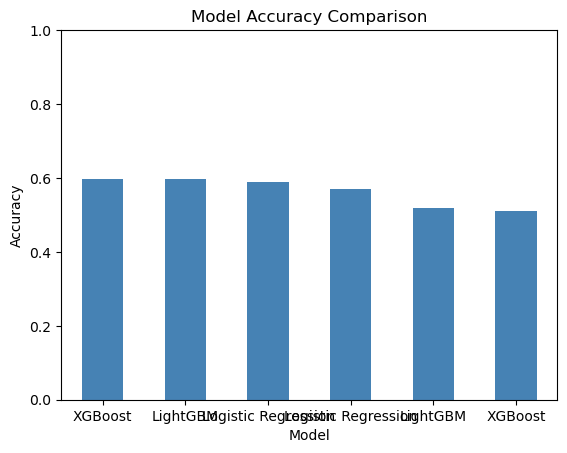

In [14]:
results_df.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    color="steelblue",
    legend=False,
    title="Model Accuracy Comparison"
)

plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()